In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    auc
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [28]:
# Step 2: Load the downloaded CSV dataset

df = pd.read_csv("train.csv")

# Display the number of rows and columns
print("Dataset Shape:", df.shape)

# Display the first five rows
display(df.head())

Dataset Shape: (3380, 28)


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0x1602,CUS_0xd40,January,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,_,809.98,26.822620,22 Years and 1 Months,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.494089,Good
1,0x1603,CUS_0xd40,February,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,31.944960,NaN,No,49.574949,118.28022162236736,Low_spent_Large_value_payments,284.629162,Good
2,0x1604,CUS_0xd40,March,Aaron Maashoh,-500,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,28.609352,22 Years and 3 Months,No,49.574949,81.699521264648,Low_spent_Medium_value_payments,331.209863,Good
3,0x1605,CUS_0xd40,April,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,31.377862,22 Years and 4 Months,No,49.574949,199.4580743910713,Low_spent_Small_value_payments,223.451310,Good
4,0x1606,CUS_0xd40,May,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,Good,809.98,24.797347,22 Years and 5 Months,No,49.574949,41.420153086217326,High_spent_Medium_value_payments,341.489231,Good


In [29]:
# Step 3: Understand the dataset

# Display all column names
print("Column Names:")
print(df.columns.tolist())

# Display dataset information
df.info()

# Display statistical summary
display(df.describe(include="all").T)

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

Column Names:
['ID', 'Customer_ID', 'Month', 'Name', 'Age', 'SSN', 'Occupation', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Credit_History_Age', 'Payment_of_Min_Amount', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance', 'Credit_Score']
<class 'pandas.DataFrame'>
RangeIndex: 3380 entries, 0 to 3379
Data columns (total 28 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        3380 non-null   str    
 1   Customer_ID               3380 non-null   str    
 2   Month                     3380 non-null   str    
 3   Name                      3051 non-null   str    
 4   Age                       3380 non-null   str 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,3380,3380,0x1602,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_ID,3380,423,CUS_0xd40,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Month,3380,8,January,423,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Name,3051,420,Aileen Wangy,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,3380,159,19,131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SSN,3380,424,#F%$D@*&8,197,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Occupation,3380,16,Doctor,264,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Annual_Income,3380,637,19114.12,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Monthly_Inhand_Salary,2852.0,NaN,NaN,NaN,4297.073879,3298.508577,468.77,1654.615,3068.915,5988.705,14710.533333
Num_Bank_Accounts,3380.0,NaN,NaN,NaN,19.075148,132.606895,0.0,3.0,6.0,8.0,1777.0


Missing Values:
ID                            0
Customer_ID                   0
Month                         0
Name                        329
Age                           0
SSN                           0
Occupation                    0
Annual_Income                 0
Monthly_Inhand_Salary       528
Num_Bank_Accounts             0
Num_Credit_Card               0
Interest_Rate                 0
Num_of_Loan                   0
Type_of_Loan                440
Delay_from_due_date           0
Num_of_Delayed_Payment      223
Changed_Credit_Limit          0
Num_Credit_Inquiries         74
Credit_Mix                    0
Outstanding_Debt              0
Credit_Utilization_Ratio      0
Credit_History_Age          308
Payment_of_Min_Amount         1
Total_EMI_per_month           1
Amount_invested_monthly     141
Payment_Behaviour             1
Monthly_Balance              47
Credit_Score                  1
dtype: int64
Duplicate Rows: 0


Credit Score Counts:
Credit_Score
Standard    1784
Poor         948
Good         647
Name: count, dtype: int64
Credit Score Percentages:
Credit_Score
Standard    52.796685
Poor        28.055638
Good        19.147677
Name: proportion, dtype: float64


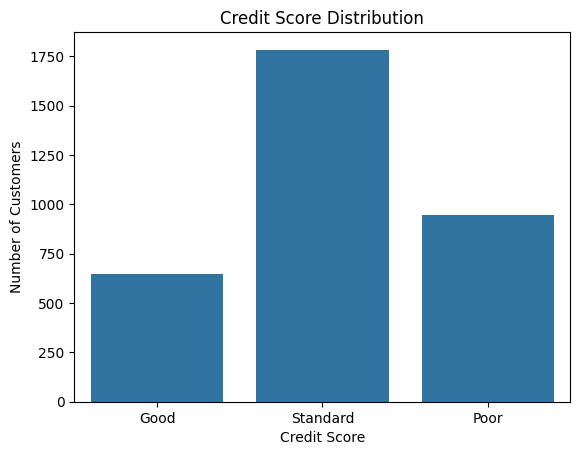

In [30]:
# Step 4: Check the target column Credit_Score

# Count each credit score category
print("Credit Score Counts:")
print(df["Credit_Score"].value_counts())

# Calculate percentage of each category
print("Credit Score Percentages:")
print(df["Credit_Score"].value_counts(normalize=True) * 100)

# Plot the distribution of credit score classes
sns.countplot(data=df, x="Credit_Score")
plt.title("Credit Score Distribution")
plt.xlabel("Credit Score")
plt.ylabel("Number of Customers")
plt.show()

In [31]:
# Step 5: Clean the dataset

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Remove unnecessary identity columns
drop_cols = [
    col for col in df.columns
    if col.strip().lower() in ["id", "customer_id", "name", "ssn"]
]

df.drop(columns=drop_cols, inplace=True, errors="ignore")

# Clean text values and remove underscores
missing_values = [
    "", "na", "n/a", "nan", "none", "null",
    "_______", "!@9#%8", "_"
]

for col in df.columns:
    if df[col].dtype == "object":
        df[col] = (
            df[col].astype("string")
            .str.strip()
            .str.replace("_", "", regex=False)
        )

        df[col] = df[col].replace(missing_values, pd.NA)

# Convert numeric-looking text columns into numbers
for col in df.columns:
    if col == "Credit_Score":
        continue

    if df[col].dtype == "object" or str(df[col].dtype) == "string":
        converted = pd.to_numeric(df[col], errors="coerce")
        original_count = df[col].notna().sum()

        if original_count > 0:
            if converted.notna().sum() / original_count >= 0.80:
                df[col] = converted

# Correct impossible age values
if "Age" in df.columns:
    df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
    df.loc[(df["Age"] < 18) | (df["Age"] > 100), "Age"] = np.nan

# Remove rows with missing target values
df = df.dropna(subset=["Credit_Score"]).copy()

# Fill missing numeric values with median and text values with mode
for col in df.columns:
    if col == "Credit_Score":
        continue

    if pd.api.types.is_numeric_dtype(df[col]):
        median_value = df[col].median()
        df[col] = df[col].fillna(
            median_value if pd.notna(median_value) else 0
        )
    else:
        mode_value = df[col].mode(dropna=True)
        fill_value = mode_value.iloc[0] if not mode_value.empty else "Unknown"
        df[col] = df[col].fillna(fill_value)

# Keep only valid credit score classes
df = df[df["Credit_Score"].isin(
    ["Good", "Standard", "Poor"]
)].copy()

# Display cleaned dataset information
print("Data Cleaning Completed!")
print("Dataset Shape:", df.shape)
print("Missing Values Remaining:", df.isnull().sum().sum())

Data Cleaning Completed!
Dataset Shape: (3379, 24)
Missing Values Remaining: 0


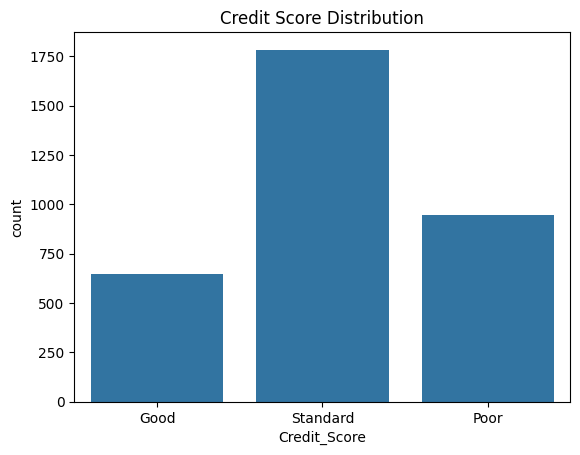

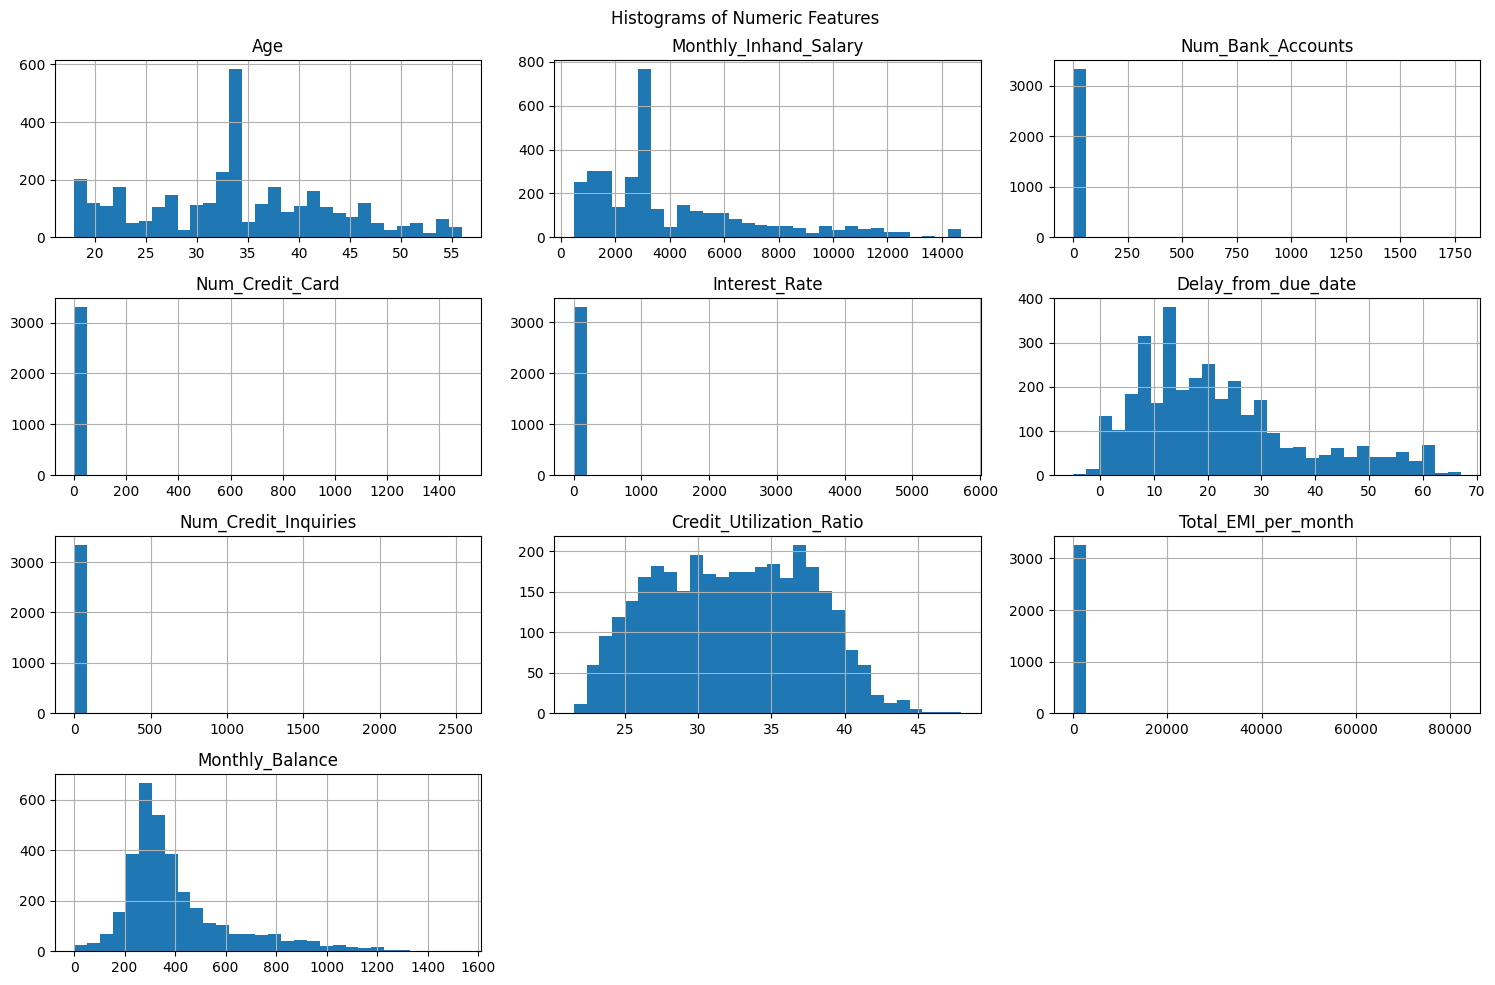

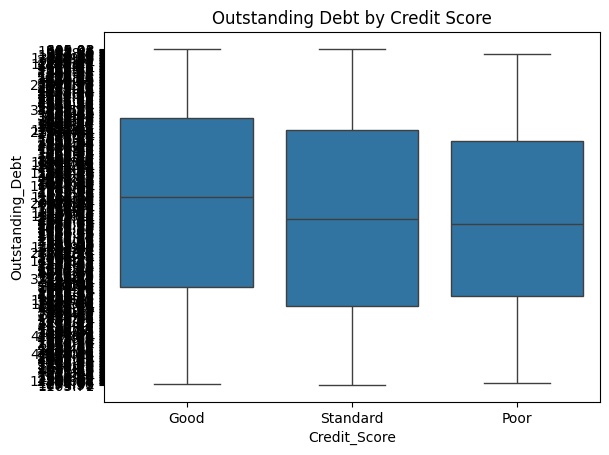

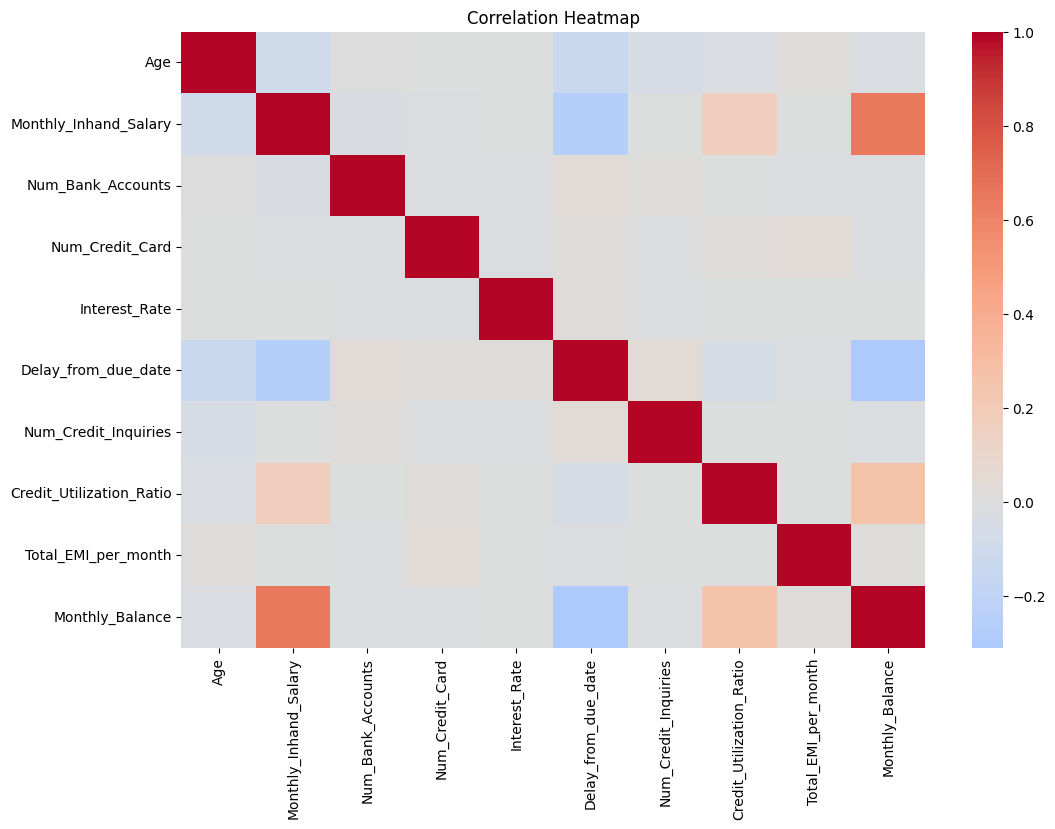

In [32]:
# Step 6.1: Plot credit score distribution

sns.countplot(data=df, x="Credit_Score")
plt.title("Credit Score Distribution")
plt.show()

# Step 6.2: Plot histograms of numeric columns

numeric_cols = df.select_dtypes(include=np.number).columns

df[numeric_cols].hist(figsize=(15, 10), bins=30)
plt.suptitle("Histograms of Numeric Features")
plt.tight_layout()
plt.show()

# Step 6.3: Plot outstanding debt by credit score

if "Outstanding_Debt" in df.columns:
    sns.boxplot(data=df, x="Credit_Score", y="Outstanding_Debt")
    plt.title("Outstanding Debt by Credit Score")
    plt.show()

# Step 6.4: Plot correlation heatmap

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))
sns.heatmap(numeric_df.corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

In [33]:
# Step 7.1: Create a new feature

if "Outstanding_Debt" in df.columns and "Annual_Income" in df.columns:
    debt = pd.to_numeric(df["Outstanding_Debt"], errors="coerce")
    income = pd.to_numeric(df["Annual_Income"], errors="coerce")

    ratio = debt / income.replace(0, np.nan)
    ratio = ratio.replace([np.inf, -np.inf], np.nan)

    df["Debt_to_Income_Ratio"] = ratio.fillna(
        ratio.median() if ratio.notna().any() else 0
    )

# Step 7.2: Separate input features X and target y

X = df.drop(columns=["Credit_Score"]).copy()
y = df["Credit_Score"].copy()

# Encode target classes into numbers
le_y = LabelEncoder()
y_encoded = le_y.fit_transform(y)

# Step 7.3: Convert categorical features into numeric columns

X = pd.get_dummies(X, drop_first=True, dtype=int)

# Replace infinite and missing values
X = X.replace([np.inf, -np.inf], np.nan).fillna(0)

# Step 7.4: Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

# Step 7.5: Select the 15 best features using SelectKBest

k = min(15, X_train.shape[1])

selector = SelectKBest(score_func=f_classif, k=k)

X_train_selected = selector.fit_transform(X_train, y_train)
X_test_selected = selector.transform(X_test)

# Display selected feature names
selected_features = X_train.columns[selector.get_support()].tolist()

print("Selected Features:")
print(selected_features)

Selected Features:
['Monthly_Inhand_Salary', 'Delay_from_due_date', 'Monthly_Balance', 'Debt_to_Income_Ratio', 'Num_of_Loan_0', 'Num_of_Loan_1', 'Num_of_Loan_6', 'Num_of_Loan_8', 'Type_of_Loan_Payday Loan', 'Num_of_Delayed_Payment_21', 'Num_of_Delayed_Payment_5', 'Credit_Mix_Good', 'Credit_Mix_Standard', 'Payment_of_Min_Amount_No', 'Payment_of_Min_Amount_Yes']


In [34]:
# Step 8: Display training and testing dataset sizes

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("Training Features Shape:", X_train_selected.shape)
print("Testing Features Shape:", X_test_selected.shape)

Training Samples: 2703
Testing Samples: 676
Training Features Shape: (2703, 15)
Testing Features Shape: (676, 15)


              precision    recall  f1-score   support

        Good       0.61      0.53      0.57       129
        Poor       0.66      0.74      0.70       190
    Standard       0.72      0.70      0.71       357

    accuracy                           0.68       676
   macro avg       0.66      0.66      0.66       676
weighted avg       0.68      0.68      0.68       676



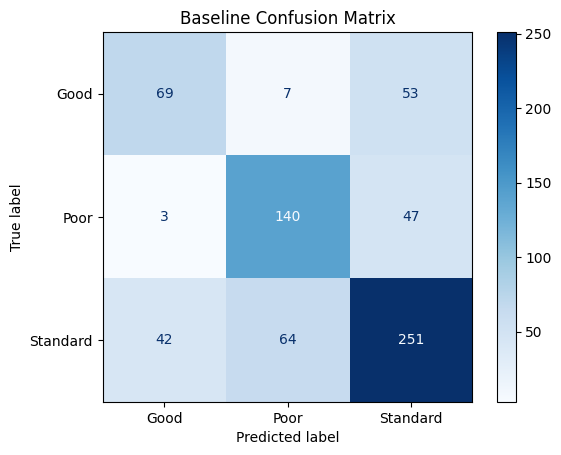

In [35]:
# Step 9: Create a function to evaluate the Decision Tree model

results = []

def evaluate(name, model):

    # Train the model
    model.fit(X_train_selected, y_train)

    # Predict training and testing results
    train_pred = model.predict(X_train_selected)
    test_pred = model.predict(X_test_selected)

    # Calculate confusion matrix
    cm = confusion_matrix(
        y_test,
        test_pred,
        labels=np.arange(len(le_y.classes_))
    )

    # Calculate specificity for each class
    specificity_values = []

    for i in range(len(le_y.classes_)):
        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = cm.sum() - tp - fn - fp

        specificity_values.append(
            tn / (tn + fp) if (tn + fp) else 0
        )

    # Calculate multiclass AUC
    try:
        probabilities = model.predict_proba(X_test_selected)

        auc_value = roc_auc_score(
            y_test,
            probabilities,
            labels=np.arange(len(le_y.classes_)),
            multi_class="ovr",
            average="macro"
        )
    except ValueError:
        auc_value = np.nan

    # Store all evaluation metrics
    result = {
        "Setting": name,
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Accuracy": accuracy_score(y_test, test_pred),
        "Precision": precision_score(
            y_test, test_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, test_pred, average="macro", zero_division=0
        ),
        "F1": f1_score(
            y_test, test_pred, average="macro", zero_division=0
        ),
        "Specificity": np.mean(specificity_values),
        "AUC": auc_value
    }

    # Add result to the results list
    results.append(result)

    return result


# Create and evaluate the baseline model
baseline_model = DecisionTreeClassifier(random_state=42)

evaluate("Baseline", baseline_model)

# Display the classification report
baseline_pred = baseline_model.predict(X_test_selected)

print(classification_report(
    y_test,
    baseline_pred,
    labels=np.arange(len(le_y.classes_)),
    target_names=le_y.classes_,
    zero_division=0
))

# Display the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    baseline_pred,
    labels=np.arange(len(le_y.classes_)),
    display_labels=le_y.classes_,
    cmap="Blues"
)

plt.title("Baseline Confusion Matrix")
plt.show()

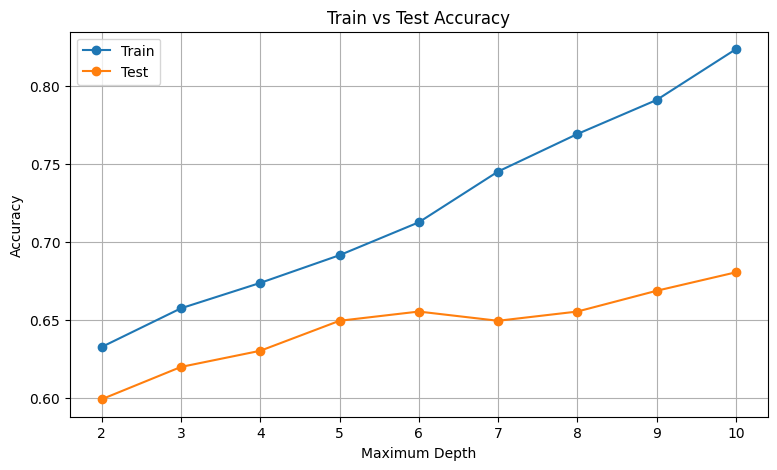

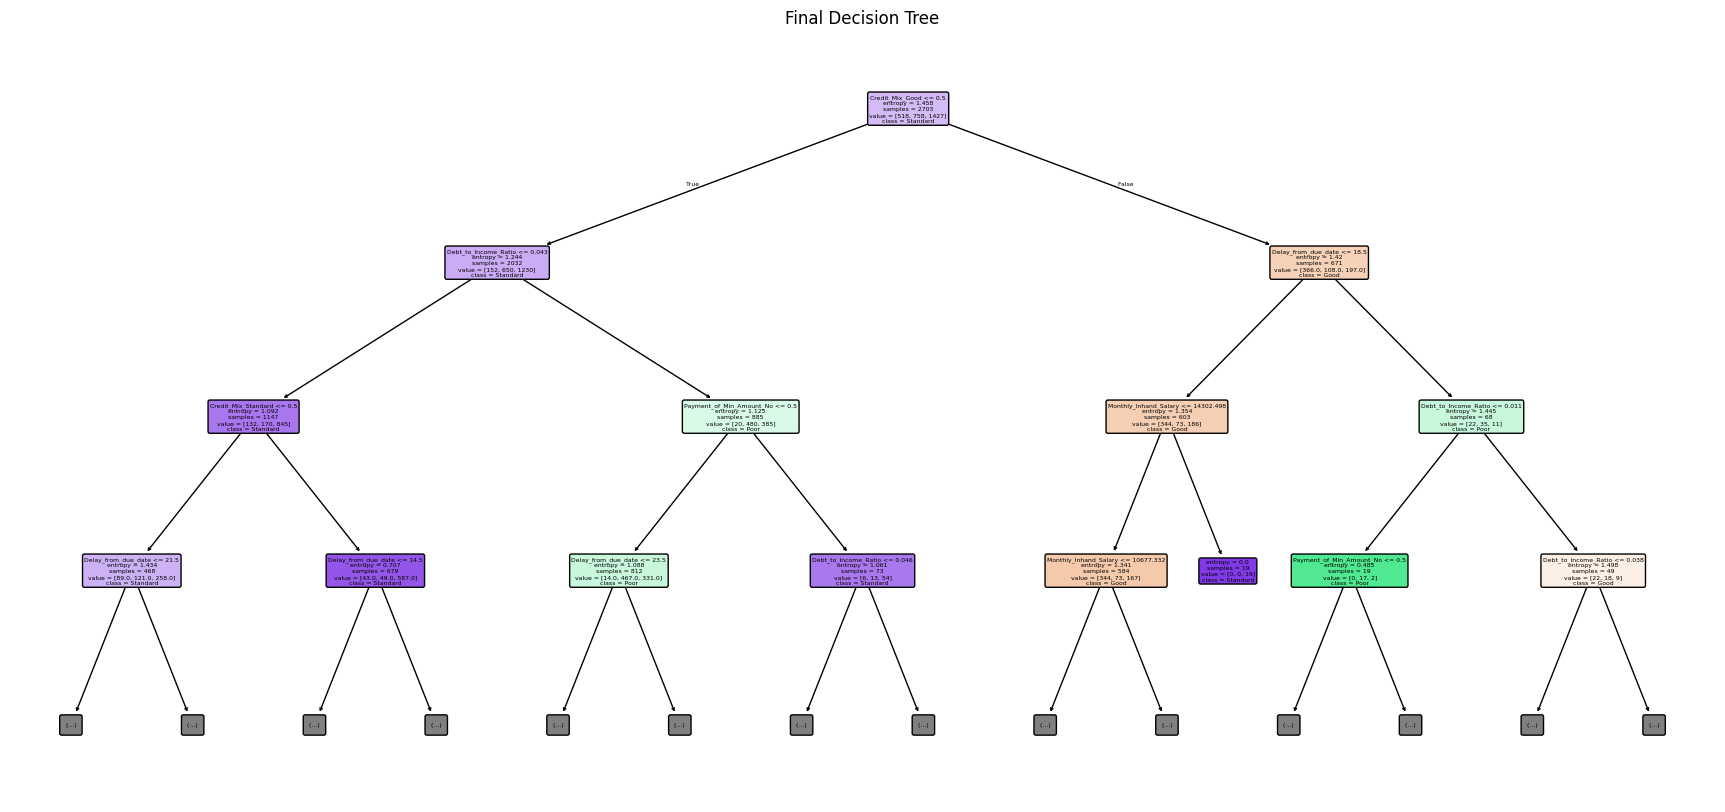

Root Node Feature: Credit_Mix_Good


,Feature,Importance
3,Debt_to_Income_Ratio,0.258057
2,Monthly_Balance,0.194419
1,Delay_from_due_date,0.164167
0,Monthly_Inhand_Salary,0.142670
11,Credit_Mix_Good,0.116469
12,Credit_Mix_Standard,0.035811
14,Payment_of_Min_Amount_Yes,0.018209
13,Payment_of_Min_Amount_No,0.018120
5,Num_of_Loan_1,0.014554
4,Num_of_Loan_0,0.009711


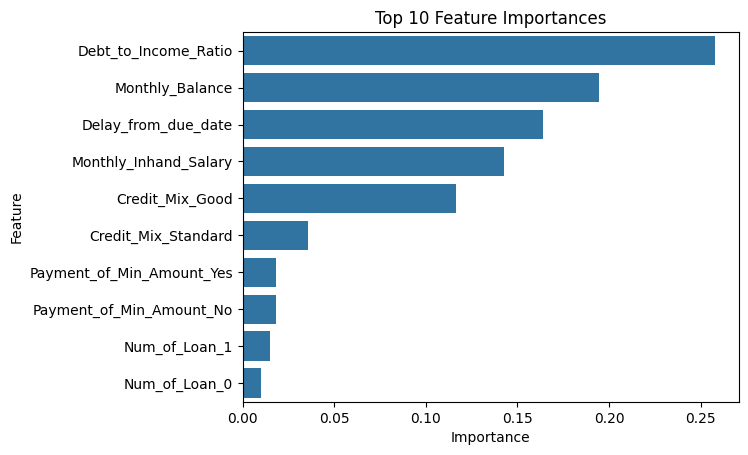

In [36]:
# Step 10.1: Compare Gini and Entropy criteria

for criterion in ["gini", "entropy"]:
    model = DecisionTreeClassifier(
        criterion=criterion,
        random_state=42
    )

    evaluate(criterion, model)


# Step 10.2: Test max_depth values from 2 to 10

depth_results = []

for depth in range(2, 11):
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    depth_results.append(
        evaluate(f"max_depth={depth}", model)
    )


# Step 10.3: Plot training and testing accuracy

depth_df = pd.DataFrame(depth_results)

plt.figure(figsize=(9, 5))
plt.plot(range(2, 11), depth_df["Train Accuracy"], marker="o", label="Train")
plt.plot(range(2, 11), depth_df["Accuracy"], marker="o", label="Test")

plt.xlabel("Maximum Depth")
plt.ylabel("Accuracy")
plt.title("Train vs Test Accuracy")
plt.xticks(range(2, 11))
plt.legend()
plt.grid(True)
plt.show()


# Step 10.4: Compare all tested settings

results_df = pd.DataFrame(results).drop_duplicates(
    subset=["Setting"], keep="last"
)

best_setting = results_df.sort_values(
    "F1", ascending=False
).iloc[0]["Setting"]


# Create the best model according to Macro F1
if best_setting == "Baseline":
    best_params = {"random_state": 42}
elif best_setting in ["gini", "entropy"]:
    best_params = {
        "criterion": best_setting,
        "random_state": 42
    }
else:
    best_params = {
        "max_depth": int(best_setting.split("=")[1]),
        "random_state": 42
    }

final_model = DecisionTreeClassifier(**best_params)
final_model.fit(X_train_selected, y_train)


# Step 10.5: Visualize the Decision Tree

plt.figure(figsize=(22, 10))

plot_tree(
    final_model,
    feature_names=selected_features,
    class_names=le_y.classes_,
    filled=True,
    rounded=True,
    max_depth=3
)

plt.title("Final Decision Tree")
plt.show()

# Display the root node feature
print("Root Node Feature:",
      selected_features[final_model.tree_.feature[0]])


# Step 10.6: Display feature importance

importance_df = pd.DataFrame({
    "Feature": selected_features,
    "Importance": final_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df.head(10))

sns.barplot(data=importance_df.head(10), x="Importance", y="Feature")
plt.title("Top 10 Feature Importances")
plt.show()

,Setting,Train Accuracy,Accuracy,Precision,Recall,F1,Specificity,AUC
0,entropy,1.0000,0.6805,0.6626,0.6657,0.6641,0.8196,0.7427
1,max_depth=10,0.8235,0.6805,0.6535,0.6682,0.6597,0.8256,0.7699
2,gini,1.0000,0.6805,0.6613,0.6583,0.6584,0.8194,0.7388
3,Baseline,1.0000,0.6805,0.6613,0.6583,0.6584,0.8194,0.7388
4,max_depth=9,0.7910,0.6686,0.6415,0.6657,0.6503,0.8251,0.7658
5,max_depth=6,0.7125,0.6553,0.6393,0.6721,0.6453,0.8236,0.7933
6,max_depth=5,0.6915,0.6494,0.6277,0.6594,0.6386,0.8155,0.7826
7,max_depth=8,0.7691,0.6553,0.6303,0.6507,0.6374,0.8159,0.7675
8,max_depth=7,0.7451,0.6494,0.6230,0.6436,0.6302,0.8134,0.7835
9,max_depth=4,0.6737,0.6302,0.6075,0.6209,0.6134,0.7964,0.7619


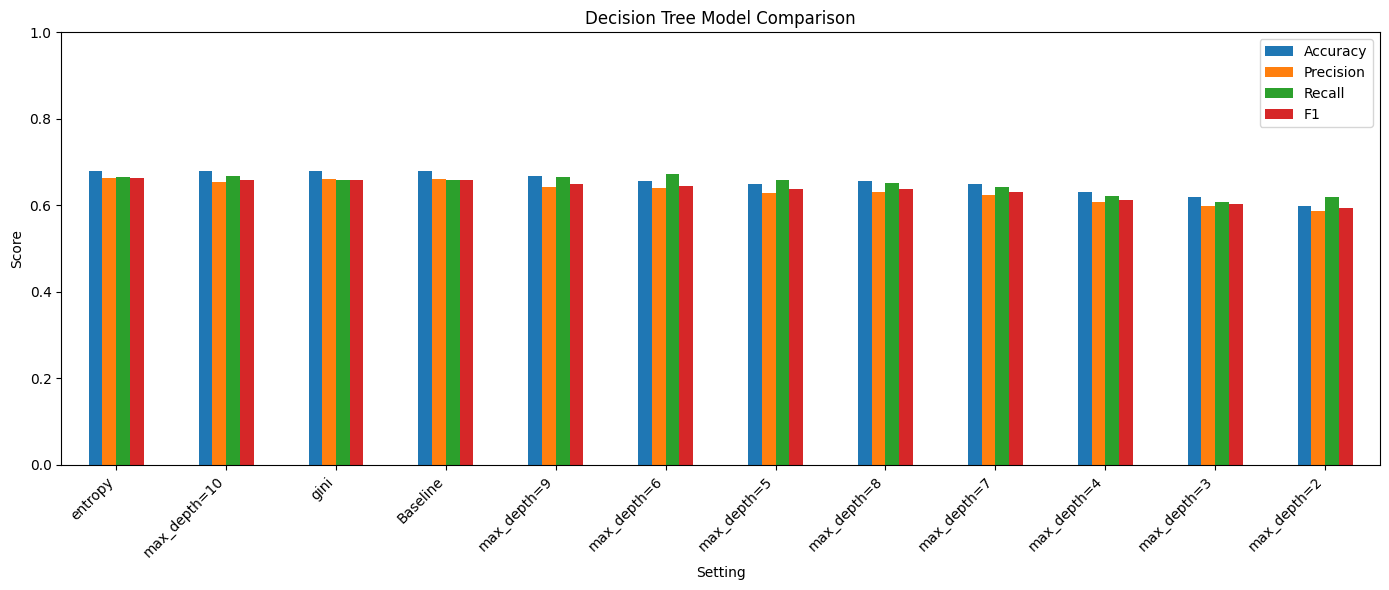

Best Setting: entropy
Final Macro F1: 0.6641294979782052


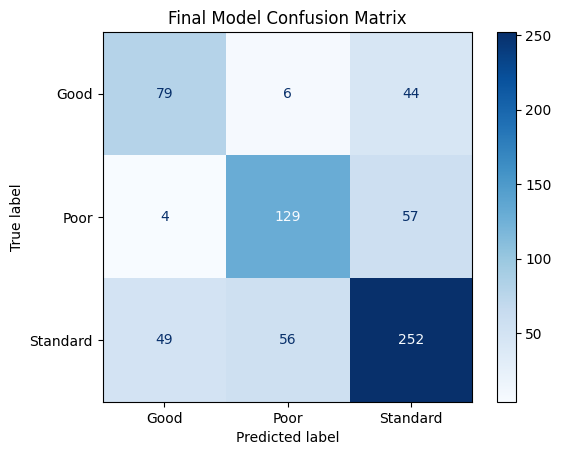

In [37]:
# Step 11.1: Create the comparison table

results_df = pd.DataFrame(results)

results_df = results_df.drop_duplicates(
    subset=["Setting"], keep="last"
)

results_df = results_df.sort_values(
    "F1", ascending=False
).reset_index(drop=True)

display(results_df.round(4))


# Step 11.2: Plot performance metrics

plot_df = results_df.set_index("Setting")[
    ["Accuracy", "Precision", "Recall", "F1"]
]

plot_df.plot(kind="bar", figsize=(14, 6))

plt.title("Decision Tree Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# Step 11.3: Select the best model using Macro F1

best_setting = results_df.iloc[0]["Setting"]

if best_setting == "Baseline":
    best_params = {"random_state": 42}
elif best_setting in ["gini", "entropy"]:
    best_params = {
        "criterion": best_setting,
        "random_state": 42
    }
else:
    best_params = {
        "max_depth": int(best_setting.split("=")[1]),
        "random_state": 42
    }

# Train the final selected model
final_model = DecisionTreeClassifier(**best_params)
final_model.fit(X_train_selected, y_train)

# Evaluate the final model
final_pred = final_model.predict(X_test_selected)

print("Best Setting:", best_setting)
print("Final Macro F1:", f1_score(
    y_test, final_pred, average="macro", zero_division=0
))

# Display final confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_pred,
    labels=np.arange(len(le_y.classes_)),
    display_labels=le_y.classes_,
    cmap="Blues"
)

plt.title("Final Model Confusion Matrix")
plt.show()

In [38]:
# Step 12: Create three sample inputs from test data

new_inputs = X_test.iloc[:3].copy()

# Modify a numeric feature slightly for demonstration
changeable_features = [
    feature for feature in selected_features
    if feature in new_inputs.columns
    and pd.api.types.is_numeric_dtype(X[feature])
]

if len(new_inputs) == 3 and changeable_features:
    feature = changeable_features[0]

    for i, factor in enumerate([0.90, 1.00, 1.10]):
        new_inputs.iloc[
            i, new_inputs.columns.get_loc(feature)
        ] = max(0, X_test.iloc[i][feature] * factor)

# Apply the same feature selection
new_inputs_selected = selector.transform(new_inputs)

# Predict credit score categories
predictions = final_model.predict(new_inputs_selected)

# Convert numeric predictions back to class names
predicted_classes = le_y.inverse_transform(predictions)

# Display predictions
prediction_results = pd.DataFrame({
    "Customer": ["Customer 1", "Customer 2", "Customer 3"],
    "Predicted Credit Score": predicted_classes
})

display(prediction_results)

,Customer,Predicted Credit Score
0,Customer 1,Standard
1,Customer 2,Standard
2,Customer 3,Standard


In [39]:
# Step 13: Display the final project summary

print("PROJECT: P35 - Credit Score Class")
print("MODEL: Decision Tree Classifier")
print("BEST SETTING:", best_setting)

print("Accuracy:", accuracy_score(y_test, final_pred))
print("Precision:", precision_score(
    y_test, final_pred, average="macro", zero_division=0
))
print("Recall:", recall_score(
    y_test, final_pred, average="macro", zero_division=0
))
print("Macro F1:", f1_score(
    y_test, final_pred, average="macro", zero_division=0
))

print("\nProject completed successfully!")

PROJECT: P35 - Credit Score Class
MODEL: Decision Tree Classifier
BEST SETTING: entropy
Accuracy: 0.6804733727810651
Precision: 0.6625861794906484
Recall: 0.6657442740458076
Macro F1: 0.6641294979782052

Project completed successfully!
